XGBoost - Credential-based Intrusion Detection

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
!pip install lime
import lime.lime_tabular
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from xgboost import XGBClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             precision_score, recall_score,
                             confusion_matrix, classification_report)

In [2]:
df = pd.read_csv("/kaggle/input/datasets/kadinawaf/credguard4/CredGuard_Io_Output1.csv")
print(df.shape)
print(df["label"].value_counts(dropna=False))

/tmp/ipykernel_50/3914520064.py:1: DtypeWarning: Columns (2,4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/kaggle/input/datasets/kadinawaf/credguard4/CredGuard_Io_Output1.csv")


(1003030, 22)
label
0.0    501998
1.0    501032
Name: count, dtype: int64


Value counts in label column:
label
0.0    501998
1.0    501032
Name: count, dtype: int64


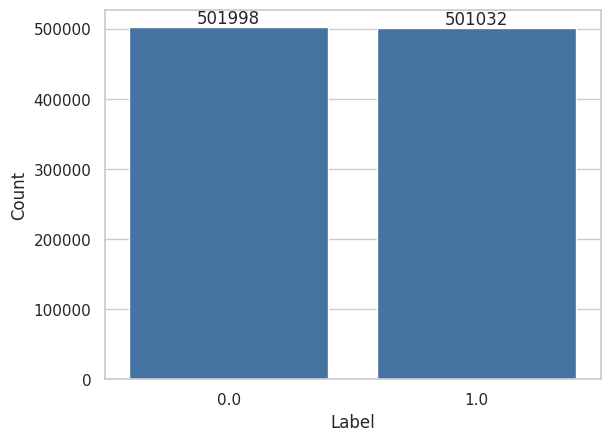

In [3]:
sns.set_theme(style="whitegrid")

ax = sns.countplot(x='label', data=df, color='#3572B0')
ax.bar_label(ax.containers[0])
plt.xlabel('Label', fontsize=12)
plt.ylabel('Count', fontsize=12)
print("Value counts in label column:")
print(df['label'].value_counts())

plt.show()

2. Configuration

In [4]:
IP_COL, USER_COL, LOC_COL, ASN_COL = "src_ip", "username", "location", "asn"
SEED = 42

Q = dict(v_fast=0.05, fast=0.20, v_reg=0.10, reg=0.30, failure=0.95)

FEATURES = [
    "hr", "dow", "is_wknd", "is_night",
    "p_len", "p_comp", "has_num", "has_spec", "p_score",
    "u_freq", "loc_freq", "asn_freq",
    "mean_iat", "std_iat", "iat_var", "is_v_fast", "is_fast", "is_reg", "is_v_reg",
    "tries", "fails", "fail_rate", "is_failure",
]

assert len(FEATURES) == 23 and len(set(FEATURES)) == 23

3. Feature Engineering and Split Functions

In [5]:
def build_row_features(df):
    X = df.copy()
    ts = pd.to_datetime(X["timestamp"], format="mixed", errors="coerce")
    missing = ts.isna()
    X["hr"] = ts.dt.hour.fillna(0).astype("int8")
    X["dow"] = ts.dt.dayofweek.fillna(0).astype("int8")
    X["is_wknd"] = (X["dow"].isin([4, 5]) & ~missing).astype("int8")
    X["is_night"] = (((X["hr"] < 6) | (X["hr"] >= 23)) & ~missing).astype("int8")

    X["p_len"] = pd.to_numeric(X["password_length"], errors="coerce").fillna(0).astype("int16")
    X["p_comp"] = pd.to_numeric(X["password_complexity"], errors="coerce").fillna(0).astype("int16")
    pw = X["password"].astype(str)
    X["has_num"] = pw.str.contains(r"\d", regex=True).astype("int8")
    X["has_spec"] = pw.str.contains(r"[^\w\s]|_", regex=True).astype("int8")
    X["p_score"] = ((X["p_comp"] * X["p_len"]) / 10).astype("float32")

    X["mean_iat"] = pd.to_numeric(X["mean_iat"], errors="coerce").fillna(0).astype("float32")
    X["std_iat"] = pd.to_numeric(X["std_iat"], errors="coerce").fillna(0).astype("float32")
    X["iat_var"] = (X["std_iat"].astype("float64") ** 2).astype("float32")

    X["tries"] = pd.to_numeric(X["login_attempt"], errors="coerce").fillna(0).astype("int16")
    X["fails"] = pd.to_numeric(X["fail_attempt"], errors="coerce").fillna(0).astype("int16")
    X["fail_rate"] = pd.to_numeric(X["fail_ratio"], errors="coerce").fillna(0).astype("float32")

    X[USER_COL] = X[USER_COL].astype(str)
    X["target"] = X["label"].astype("int8")
    return X


def group_split(X_all):
    g1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
    tr, tmp = next(g1.split(X_all, X_all["target"], groups=X_all[IP_COL]))
    train, temp = X_all.iloc[tr].copy(), X_all.iloc[tmp].copy()
    g2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=SEED)
    va, te = next(g2.split(temp, temp["target"], groups=temp[IP_COL]))
    val, test = temp.iloc[va].copy(), temp.iloc[te].copy()
    a, b, c = set(train[IP_COL]), set(val[IP_COL]), set(test[IP_COL])
    assert a.isdisjoint(b) and a.isdisjoint(c) and b.isdisjoint(c), "IP overlap!"
    return train, val, test


class TrainFitted:
    def fit(self, train):
        self.u_map = train[USER_COL].value_counts(normalize=True)
        self.loc_map = train[LOC_COL].value_counts(normalize=True)
        self.asn_map = train[ASN_COL].value_counts(normalize=True)
        q = lambda c, p: float(train[c].quantile(p))
        self.t = dict(v_fast=q("mean_iat", Q["v_fast"]), fast=q("mean_iat", Q["fast"]),
                      v_reg=q("std_iat", Q["v_reg"]), reg=q("std_iat", Q["reg"]),
                      failure=q("fail_rate", Q["failure"]))
        return self

    def transform(self, df):
        d, t = df.copy(), self.t
        d["u_freq"] = d[USER_COL].map(self.u_map).fillna(0).astype("float32")
        d["loc_freq"] = d[LOC_COL].map(self.loc_map).fillna(0).astype("float32")
        d["asn_freq"] = d[ASN_COL].map(self.asn_map).fillna(0).astype("float32")
        d["is_v_fast"] = (d["mean_iat"] < t["v_fast"]).astype("int8")
        d["is_fast"] = ((d["mean_iat"] >= t["v_fast"]) & (d["mean_iat"] < t["fast"])).astype("int8")
        d["is_v_reg"] = (d["std_iat"] < t["v_reg"]).astype("int8")
        d["is_reg"] = ((d["std_iat"] >= t["v_reg"]) & (d["std_iat"] < t["reg"])).astype("int8")
        d["is_failure"] = (d["fail_rate"] >= t["failure"]).astype("int8")
        return d


def featurize(train, val, test):
    st = TrainFitted().fit(train)
    tr, va, te = st.transform(train), st.transform(val), st.transform(test)
    return dict(X_train=tr[FEATURES], y_train=tr["target"],
                X_val=va[FEATURES], y_val=va["target"],
                X_test=te[FEATURES], y_test=te["target"])

4. Data Preparation

In [6]:
X_all = build_row_features(df)
train, val, test = group_split(X_all)
S = featurize(train, val, test)

X_train, y_train = S["X_train"], S["y_train"]
X_val,   y_val   = S["X_val"],   S["y_val"]
X_test,  y_test  = S["X_test"],  S["y_test"]

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.value_counts())

(755190, 23) (129328, 23) (118512, 23)
target
1    388585
0    366605
Name: count, dtype: int64


5. Split Sizes

In [7]:
splits = {"Train": train, "Validation": val, "Test": test}
sizes_df = pd.DataFrame({
    "Split": list(splits.keys()),
    "Rows": [len(d) for d in splits.values()],
    "Unique IPs": [d[IP_COL].nunique() for d in splits.values()],
    "Normal": [int((d["target"] == 0).sum()) for d in splits.values()],
    "Attack": [int((d["target"] == 1).sum()) for d in splits.values()],
})
sizes_df["Attack %"] = (sizes_df["Attack"] / sizes_df["Rows"] * 100).round(2)
sizes_df

,Split,Rows,Unique IPs,Normal,Attack,Attack %
0,Train,755190,60122,366605,388585,51.46
1,Validation,129328,12883,68372,60956,47.13
2,Test,118512,12884,67021,51491,43.45


6. Hyperparameter Search (selected on validation only)

In [8]:
configs = [
    dict(max_depth=4, min_child_weight=5,  subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0),
    dict(max_depth=6, min_child_weight=10, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0),
    dict(max_depth=6, min_child_weight=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0),
    dict(max_depth=8, min_child_weight=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=10.0),
    dict(max_depth=5, min_child_weight=50, subsample=0.7, colsample_bytree=0.7, reg_lambda=10.0),
    dict(max_depth=3, min_child_weight=10, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0),
]

rng = np.random.RandomState(SEED)
pos = rng.choice(len(X_train), size=min(250000, len(X_train)), replace=False)
X_s, y_s = X_train.iloc[pos], y_train.iloc[pos]

search_rows = []
for i, cfg in enumerate(configs):
    m = XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        tree_method="hist",
        eval_metric="logloss",
        early_stopping_rounds=30,
        n_jobs=-1,
        random_state=SEED,
        **cfg
    )
    m.fit(X_s, y_s, eval_set=[(X_val, y_val)], verbose=False)
    p = m.predict_proba(X_val)[:, 1]
    search_rows.append({
        "Config": i,
        "max_depth": cfg["max_depth"],
        "min_child_weight": cfg["min_child_weight"],
        "reg_lambda": cfg["reg_lambda"],
        "subsample": cfg["subsample"],
        "Val Accuracy (%)": round(accuracy_score(y_val, (p >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_val, p), 4),
    })

search_df = pd.DataFrame(search_rows)
best_params = configs[int(search_df["Val ROC-AUC"].idxmax())]
print("Best params:", best_params)
search_df

Best params: {'max_depth': 8, 'min_child_weight': 30, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 10.0}


,Config,max_depth,min_child_weight,reg_lambda,subsample,Val Accuracy (%),Val ROC-AUC
0,0,4,5,1.0,0.8,86.33,0.9410
1,1,6,10,1.0,0.8,86.42,0.9417
2,2,6,30,5.0,0.8,86.49,0.9423
3,3,8,30,10.0,0.8,86.43,0.9430
4,4,5,50,10.0,0.7,86.44,0.9400
5,5,3,10,1.0,0.8,85.46,0.9332


7. Model Creation

In [9]:
xgb = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    tree_method="hist",
    eval_metric="logloss",
    early_stopping_rounds=50,
    n_jobs=-1,
    random_state=SEED,
)

8. Training and Threshold Selection

In [10]:
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print("Best iteration:", xgb.best_iteration)

p_train = xgb.predict_proba(X_train)[:, 1]
p_val = xgb.predict_proba(X_val)[:, 1]
p_test = xgb.predict_proba(X_test)[:, 1]

grid = np.arange(0.30, 0.701, 0.01)
f1_grid = [f1_score(y_val, (p_val >= t).astype(int)) for t in grid]
thr = float(grid[int(np.argmax(f1_grid))])
print("Selected threshold:", round(thr, 2))

Best iteration: 585
Selected threshold: 0.51


In [11]:

print("--- XGBoost Hyperparameters ---")
print("n_estimators:", xgb.n_estimators)
print("learning_rate:", xgb.learning_rate)
print("tree_method:", xgb.tree_method)
print("eval_metric:", xgb.eval_metric)
print("Early Stopping Rounds:", xgb.early_stopping_rounds)

--- XGBoost Hyperparameters ---
n_estimators: 1000
learning_rate: 0.05
tree_method: hist
eval_metric: logloss
Early Stopping Rounds: 50


9. Final Results Table

In [12]:
def result_row(name, y, p, t):
    pred = (p >= t).astype(int)
    return {
        "Experiment": name,
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 2),
        "Precision (%)": round(precision_score(y, pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y, pred, zero_division=0) * 100, 2),
        "F1 (%)": round(f1_score(y, pred, zero_division=0) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y, p), 4),
    }

results_df = pd.DataFrame([
    result_row("Validation (threshold 0.50)", y_val, p_val, 0.5),
    result_row("Test (threshold 0.50)", y_test, p_test, 0.5),
    result_row(f"Validation (threshold {thr:.2f})", y_val, p_val, thr),
    result_row(f"Test (threshold {thr:.2f})", y_test, p_test, thr),
])

sizes_df.to_csv("xgb_split_sizes.csv", index=False)
search_df.to_csv("xgb_hyperparameter_search.csv", index=False)
results_df.to_csv("xgb_final_results.csv", index=False)
results_df

,Experiment,Accuracy (%),Precision (%),Recall (%),F1 (%),ROC-AUC
0,Validation (threshold 0.50),87.08,85.46,87.48,86.46,0.9455
1,Test (threshold 0.50),81.31,79.16,77.34,78.24,0.8938
2,Validation (threshold 0.51),87.15,85.80,87.14,86.47,0.9455
3,Test (threshold 0.51),81.32,79.45,76.91,78.16,0.8938


10. Model Evaluation

Accuracy Scores:
  • Training: 0.9069
  • Test: 0.8132
  • Validation: 0.8715
  • F1-Score (Weighted): 0.8129
Unique in y_test: [0 1]
Unique in y_test_pred: [0 1]


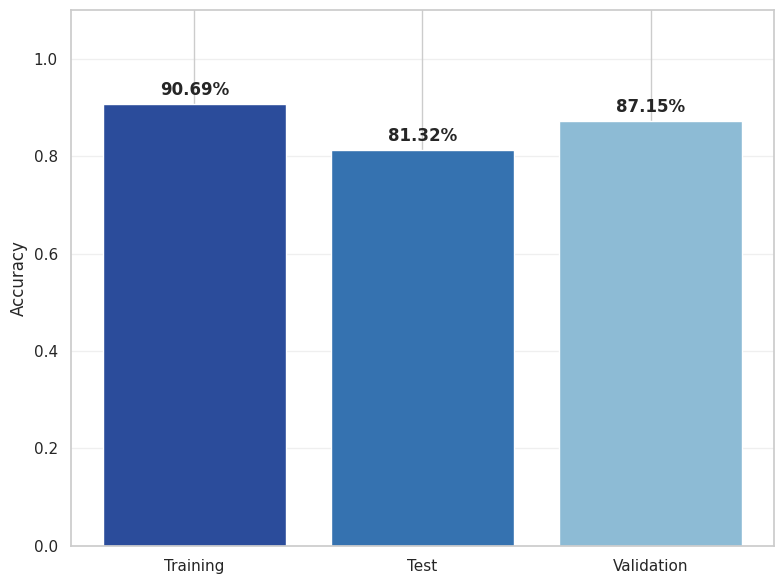

In [13]:
y_train_pred = (p_train >= thr).astype(int)
y_val_pred = (p_val >= thr).astype(int)
y_test_pred = (p_test >= thr).astype(int)

train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='weighted')

print("Accuracy Scores:")
print(f"  • Training: {train_acc:.4f}")
print(f"  • Test: {test_acc:.4f}")
print(f"  • Validation: {val_acc:.4f}")
print(f"  • F1-Score (Weighted): {test_f1:.4f}")

print("Unique in y_test:", np.unique(y_test))
print("Unique in y_test_pred:", np.unique(y_test_pred))

plt.figure(figsize=(8, 6))
accuracies = [train_acc, test_acc, val_acc]
bars = plt.bar(['Training', 'Test', 'Validation'], accuracies,
               color=['#2B4C9B', '#3572B0', '#8DBBD5'])

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
             f'{acc:.2%}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.ylim(0, 1.1)
plt.ylabel('Accuracy', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

11. Class Distribution

In [14]:
class_names = ['Normal', 'Attack']

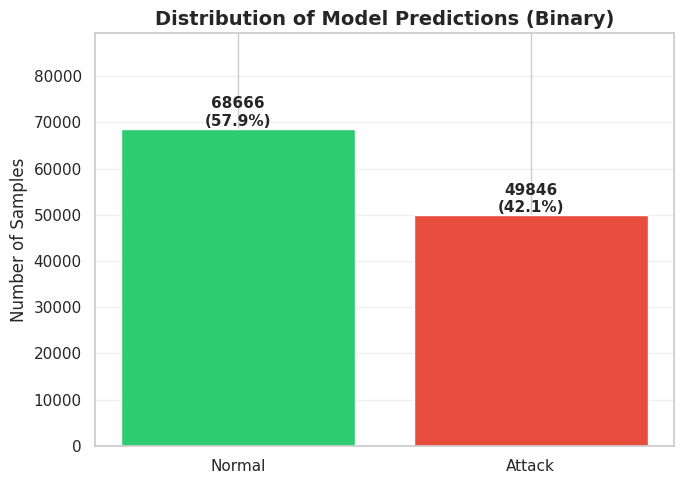

In [15]:
plt.figure(figsize=(7, 5))
colors = ['#2ECC71', '#E74C3C']

class_counts = pd.Series(y_test_pred).value_counts().sort_index()
total = len(y_test_pred)

bars = plt.bar(class_names, [class_counts.get(i, 0) for i in range(2)], color=colors)

plt.ylim(0, class_counts.max() * 1.3)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}\n({height/total*100:.1f}%)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Distribution of Model Predictions (Binary)', fontsize=14, fontweight='bold')
plt.ylabel('Number of Samples', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

12. Mutual Information

Top 15 Mutual Information Scores:
       Feature  MI_Score
11    asn_freq  0.266377
10    loc_freq  0.193346
13     std_iat  0.191986
12    mean_iat  0.188815
21   fail_rate  0.132310
9       u_freq  0.127680
20       fails  0.108089
14     iat_var  0.097292
19       tries  0.074336
22  is_failure  0.047422
17      is_reg  0.040763
0           hr  0.031357
6      has_num  0.031162
3     is_night  0.018486
16     is_fast  0.016429


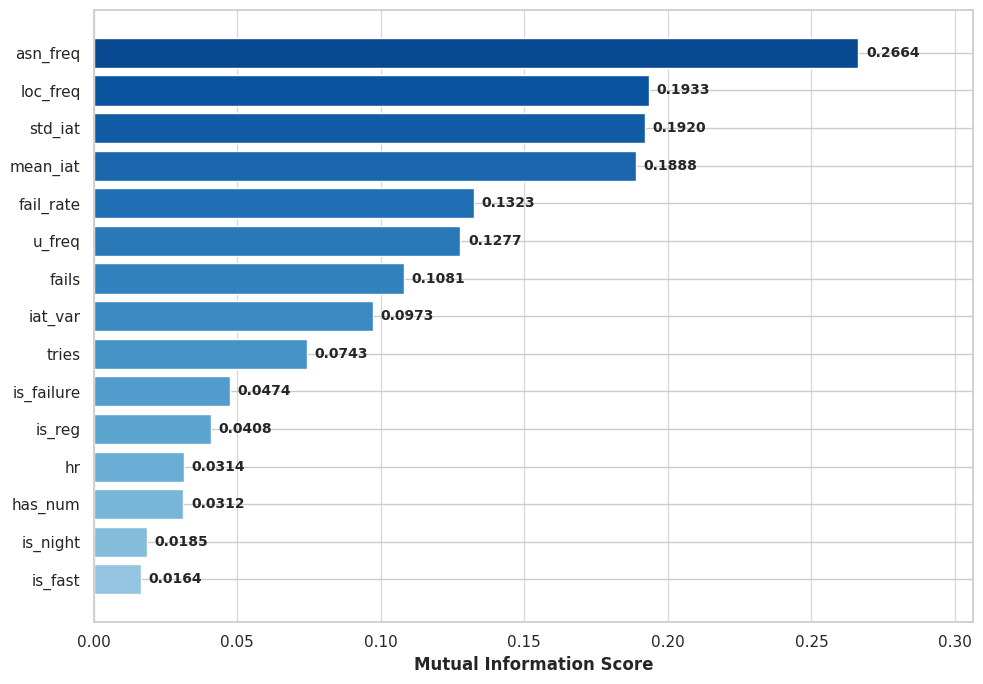

In [16]:
feature_columns = X_train.columns

X_train_df = X_train.fillna(0)

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_train_df), size=min(20000, len(X_train_df)), replace=False)
X_sample = X_train_df.iloc[sample_idx]
y_sample = y_train.iloc[sample_idx]

mi_scores = mutual_info_classif(X_sample, y_sample, random_state=42)

mi_df = pd.DataFrame({
    'Feature': feature_columns,
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

print("Top 15 Mutual Information Scores:")
print(mi_df.head(15))

plt.figure(figsize=(10, 7))
top_15_mi = mi_df.head(15)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_15_mi)))

bars = plt.barh(range(len(top_15_mi)), top_15_mi['MI_Score'].values, color=colors[::-1])

plt.grid(visible=True, axis='x', color='black', linestyle='-', alpha=0.15)
plt.yticks(range(len(top_15_mi)), top_15_mi['Feature'].values)
plt.xlabel('Mutual Information Score', fontsize=12, fontweight='bold')

plt.gca().invert_yaxis()
plt.xlim(0, top_15_mi['MI_Score'].max() * 1.15)

for i, (bar, val) in enumerate(zip(bars, top_15_mi['MI_Score'].values)):
    plt.text(
        bar.get_width() + (top_15_mi['MI_Score'].max() * 0.01),
        bar.get_y() + bar.get_height()/2,
        f'{val:.4f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

13. Feature Importance

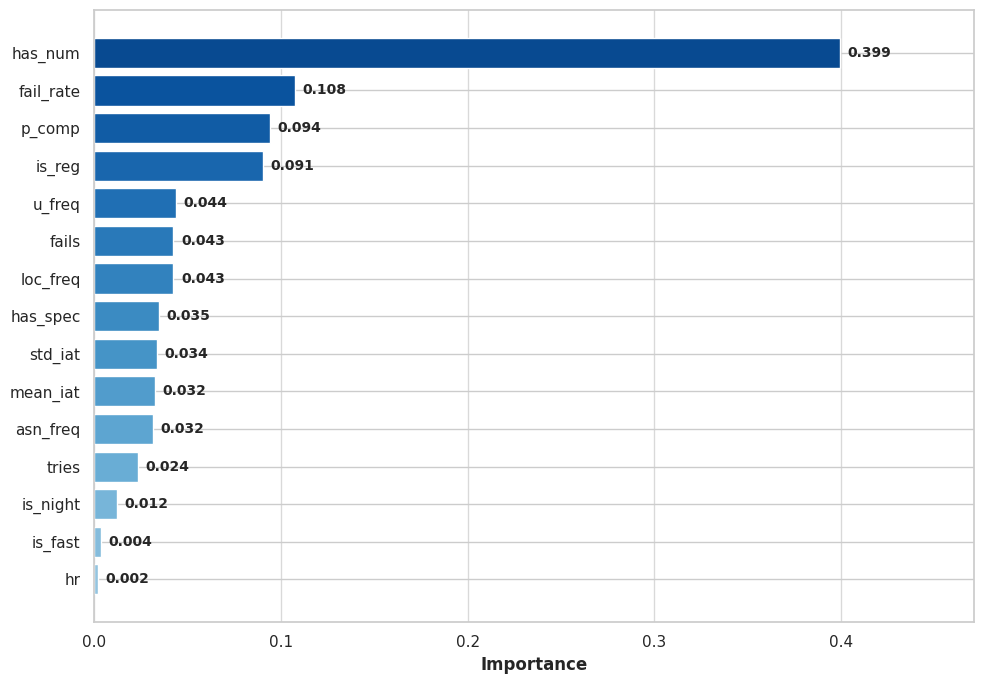

In [17]:
top_features = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 7))
top_15 = top_features.head(15)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_15)))
bars = plt.barh(range(len(top_15)), top_15['Importance'].values, color=colors[::-1])

plt.grid(visible=True, axis='x', color='black', linestyle='-', alpha=0.15)
plt.yticks(range(len(top_15)), top_15['Feature'].values)
plt.xlabel('Importance', fontsize=12, fontweight='bold')
plt.gca().invert_yaxis()
plt.xlim(0, top_15['Importance'].max() * 1.18)
for i, (bar, val) in enumerate(zip(bars, top_15['Importance'].values)):
    plt.text(
        bar.get_width() + (top_15['Importance'].max() * 0.01),
        bar.get_y() + bar.get_height()/2,
        f'{val:.3f}',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

14. Classification Report

In [18]:
report_dict = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report_dict).transpose()

for col in ['precision', 'recall', 'f1-score']:
    df_report[col] = df_report[col].apply(lambda x: f"{x*100:.2f}%")

display(df_report)

,precision,recall,f1-score,support
Normal,82.69%,84.72%,83.69%,67021.000000
Attack,79.45%,76.91%,78.16%,51491.000000
accuracy,81.32%,81.32%,81.32%,0.813243
macro avg,81.07%,80.81%,80.92%,118512.000000
weighted avg,81.28%,81.32%,81.29%,118512.000000


In [43]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

y_pred = xgb.predict(X_test)
y_score = xgb.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
auc = roc_auc_score(y_test, y_score)

print("XGBoost Confusion Matrix:")
print(cm)

print("\nXGBoost Metrics:")
print(f"Accuracy:  {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall:    {recall*100:.2f}%")
print(f"F1-score:  {f1*100:.2f}%")
print(f"ROC-AUC:   {auc:.4f}")

XGBoost Confusion Matrix:
[[56535 10486]
 [11668 39823]]

XGBoost Metrics:
Accuracy:  81.31%
Precision: 79.16%
Recall:    77.34%
F1-score:  78.24%
ROC-AUC:   0.8938


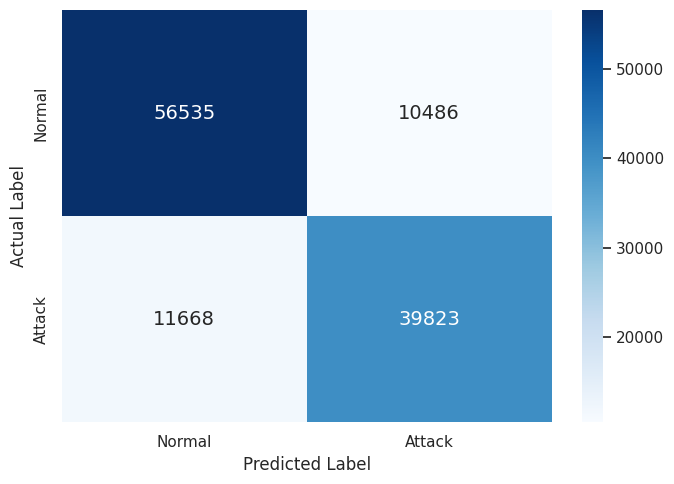

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = xgb.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"],
    annot_kws={"size": 14}
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.tight_layout()
plt.savefig(
    "XGBoost_Confusion_Matrix.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

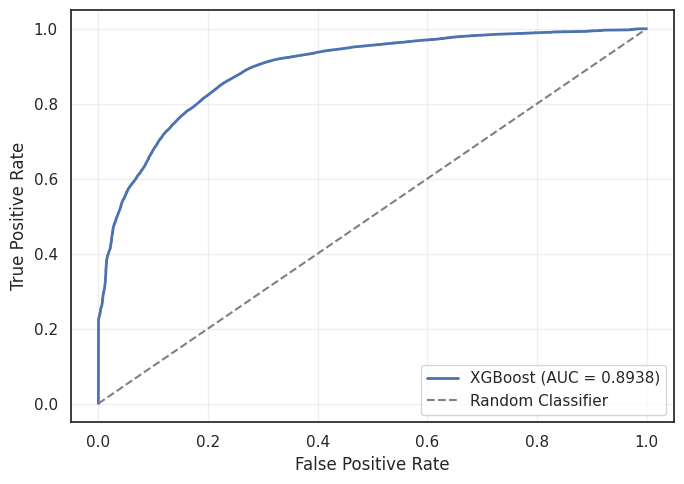

ROC-AUC: 0.8938


In [56]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_score = xgb.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_score,
    pos_label=1
)

auc_value = roc_auc_score(y_test, y_score)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"XGBoost (AUC = {auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "XGBoost_ROC_Curve.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("ROC-AUC:", round(auc_value, 4))

In [41]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("XGBoost Confusion Matrix:")
print(cm)

print("\nTN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])
print("Total:", cm.sum())

XGBoost Confusion Matrix:
[[56535 10486]
 [11668 39823]]

TN: 56535
FP: 10486
FN: 11668
TP: 39823
Total: 118512


In [40]:
y_pred = xgb.predict(X_test)

# Generate prediction probabilities
y_score = xgb.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")
print("y_pred shape:", y_pred.shape)
print("y_score shape:", y_score.shape)

Predictions generated successfully!
y_pred shape: (118512,)
y_score shape: (118512,)


15. Pearson Correlation Matrix

In [19]:

positive_iat = X_train.loc[
    X_train['mean_iat'] > 0, 'mean_iat'
]

fast_limit = positive_iat.quantile(0.05)

print("New Fast Threshold:", fast_limit)

for ds in [X_train, X_val, X_test]:
    ds['is_v_fast'] = (
        (ds['mean_iat'] > 0) &
        (ds['mean_iat'] <= fast_limit)
    ).astype('int8')

print("\nTrain distribution:")
print(X_train['is_v_fast'].value_counts())

print("\nValidation distribution:")
print(X_val['is_v_fast'].value_counts())

print("\nTest distribution:")
print(X_test['is_v_fast'].value_counts())

New Fast Threshold: 2.8081481099128722

Train distribution:
is_v_fast
0    720449
1     34741
Name: count, dtype: int64

Validation distribution:
is_v_fast
0    124199
1      5129
Name: count, dtype: int64

Test distribution:
is_v_fast
0    116797
1      1715
Name: count, dtype: int64


In [20]:
FEATURES = [
    'hr', 'dow', 'is_wknd', 'is_night',
    'p_len', 'p_comp', 'has_num', 'has_spec',
    'p_score', 'u_freq', 'loc_freq', 'asn_freq',
    'mean_iat', 'std_iat', 'iat_var',
    'is_v_fast', 'is_fast', 'is_reg', 'is_v_reg',
    'tries', 'fails', 'fail_rate', 'is_failure'
]

X_train_final = X_train[FEATURES].copy()
X_val_final = X_val[FEATURES].copy()
X_test_final = X_test[FEATURES].copy()

print("Train shape:", X_train_final.shape)
print("Validation shape:", X_val_final.shape)
print("Test shape:", X_test_final.shape)

Train shape: (755190, 23)
Validation shape: (129328, 23)
Test shape: (118512, 23)


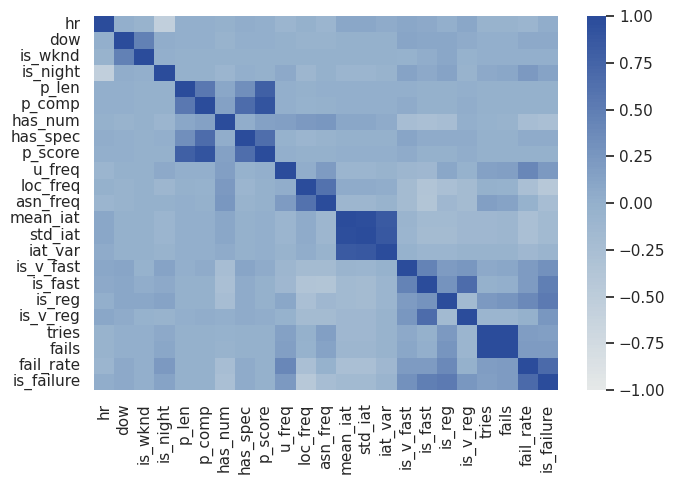

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

corr_matrix = X_train_final.corr(method='pearson')

colors = ["#E5E8E8", "#94B0CC", "#2B4C9B"]

custom_cmap = LinearSegmentedColormap.from_list(
    "gray_to_blue", colors, N=100
)

plt.figure(figsize=(7, 5))
sns.set_style("white")

sns.heatmap(
    corr_matrix,
    cmap=custom_cmap,
    annot=False,
    vmin=-1,
    vmax=1,
    center=0
)

plt.tight_layout()
plt.show()


In [36]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nClass distribution:")
print(y_test.value_counts() if hasattr(y_test, "value_counts") else __import__("numpy").unique(y_test, return_counts=True))

print("\nUnique labels:")
print(__import__("numpy").unique(y_test))

print("\nNumber of samples:")
print(len(X_test), len(y_test))

X_test shape: (118512, 23)
y_test shape: (118512,)

Class distribution:
target
0    67021
1    51491
Name: count, dtype: int64

Unique labels:
[0 1]

Number of samples:
118512 118512


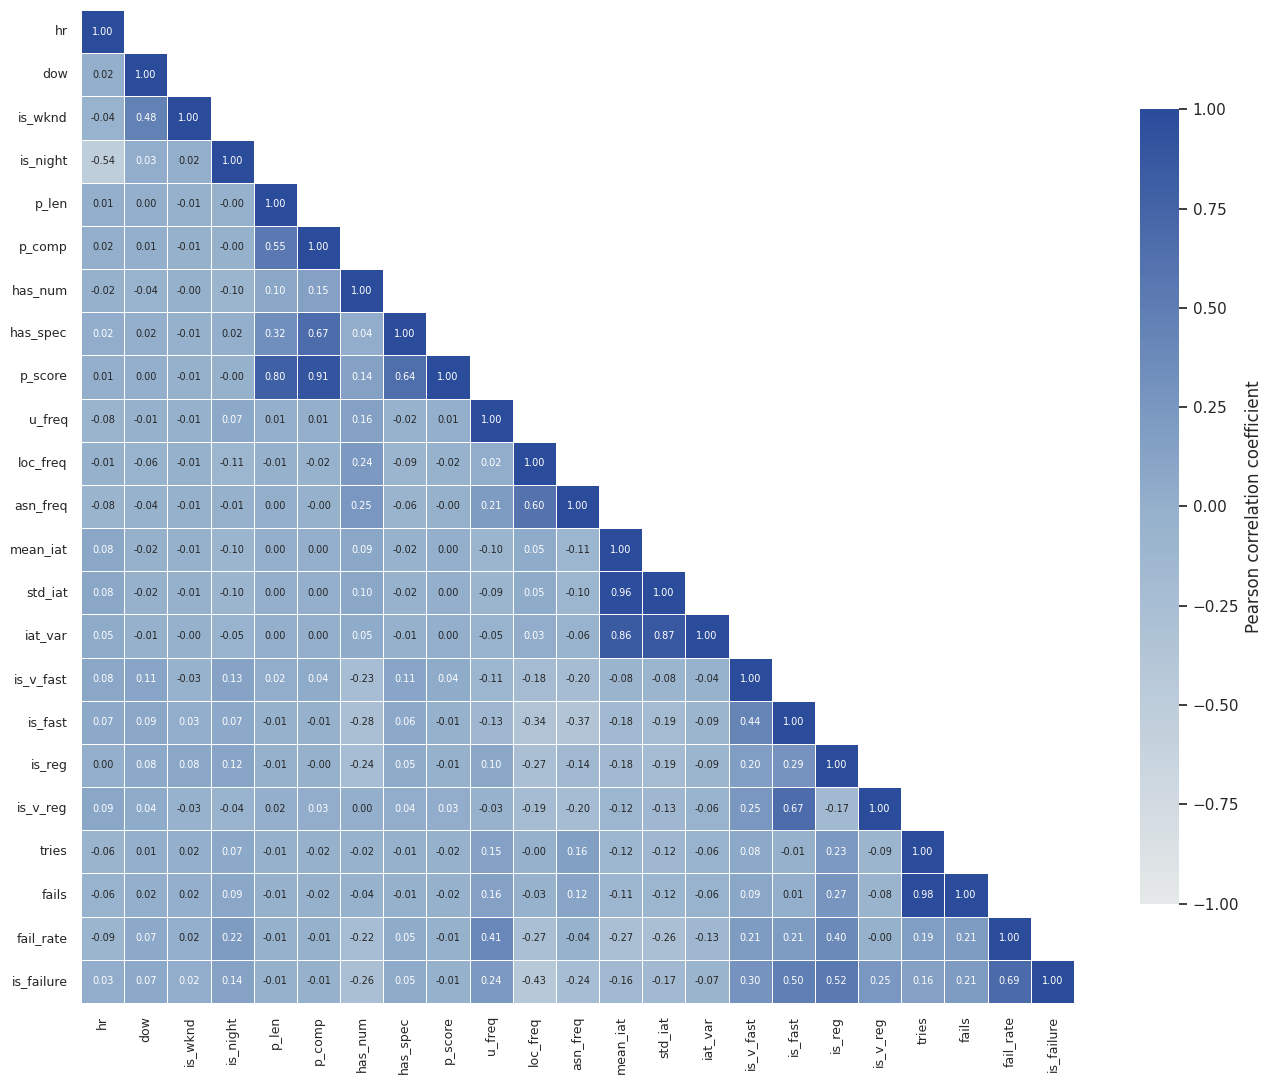

,Feature 1,Feature 2,Pearson r
0,fails,tries,0.984
1,std_iat,mean_iat,0.965
2,p_score,p_comp,0.906
3,iat_var,std_iat,0.869
4,iat_var,mean_iat,0.859
5,p_score,p_len,0.795
6,is_failure,fail_rate,0.695
7,has_spec,p_comp,0.674
8,is_v_reg,is_fast,0.667
9,p_score,has_spec,0.641


In [22]:
corr_matrix = X_train.corr(method="pearson", numeric_only=True)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

colors = ["#E5E8E8", "#94B0CC", "#2B4C9B"]
custom_cmap = LinearSegmentedColormap.from_list("gray_to_blue", colors, N=100)

plt.figure(figsize=(14, 11))
sns.set_style("white")
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap=custom_cmap,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Pearson correlation coefficient", "shrink": 0.8}
)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

pairs = (
    corr_matrix.where(~mask & (np.eye(len(corr_matrix)) == 0))
    .stack()
    .reset_index()
)
pairs.columns = ["Feature 1", "Feature 2", "Pearson r"]
pairs["abs r"] = pairs["Pearson r"].abs()
top_pairs = pairs.sort_values("abs r", ascending=False).drop(columns="abs r").head(15).reset_index(drop=True)
top_pairs["Pearson r"] = top_pairs["Pearson r"].round(3)
top_pairs

17. Classification Report Heatmap

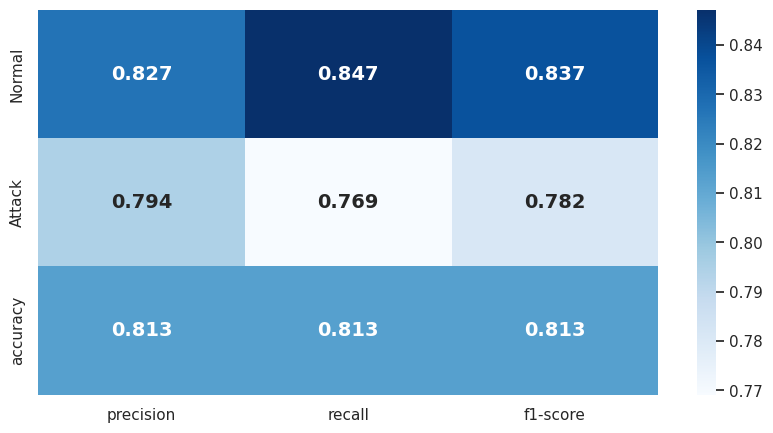

In [24]:
report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).iloc[:-1, :3].T

plt.figure(figsize=(10, 5))
sns.heatmap(report_df, annot=True, fmt=".3f",
            cmap="Blues", annot_kws={"size": 14, "weight": "bold"})
plt.show()

18. Operational Performance and Security Metrics

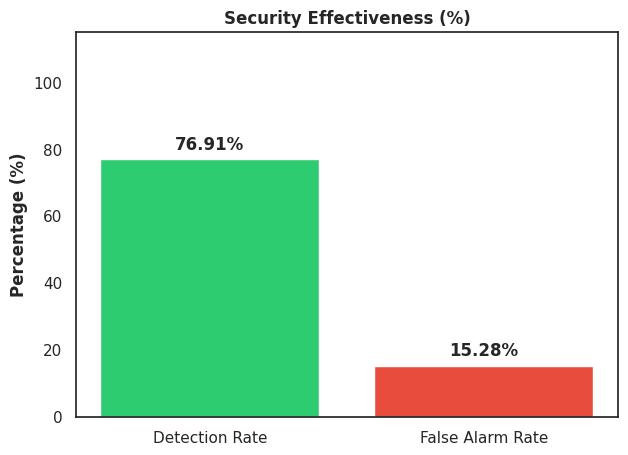

In [25]:
attack_recall = report['Attack']['recall']
normal_recall = report['Normal']['recall']

detection_rate = attack_recall * 100
far_rate = (1 - normal_recall) * 100

fig, ax1 = plt.subplots(figsize=(7, 5))

metrics = ['Detection Rate', 'False Alarm Rate']
values = [detection_rate, far_rate]

ax1.bar(metrics, values, color=['#2ECC71', '#E74C3C'])

ax1.set_ylim(0, 115)
ax1.set_title('Security Effectiveness (%)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Percentage (%)', fontweight='bold')

for i, v in enumerate(values):
    ax1.text(i, v + 3, f"{v:.2f}%", ha='center', fontweight='bold')

plt.show()

XAI- SHAP and LIME

19. SHAP Explanation

In [26]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X_test), size=min(500, len(X_test)), replace=False)
X_sample_for_explainer = X_test.iloc[idx]
feature_names_list = X_test.columns.tolist()

print("SHAP Explanation (XGB):")
explainer = shap.TreeExplainer(xgb)
shap_raw = explainer.shap_values(X_sample_for_explainer, check_additivity=False)

if isinstance(shap_raw, list):
    sv = np.array(shap_raw[1])
elif shap_raw.ndim == 3:
    sv = shap_raw[:, :, 1]
else:
    sv = shap_raw

shap_values_class_1 = sv
shap_values_class_0 = -sv
print(f"SHAP values shape: {sv.shape}")

SHAP Explanation (XGB):
SHAP values shape: (500, 23)


20. SHAP Beeswarm Plots


Beeswarm Plot - Class 0 (Normal)


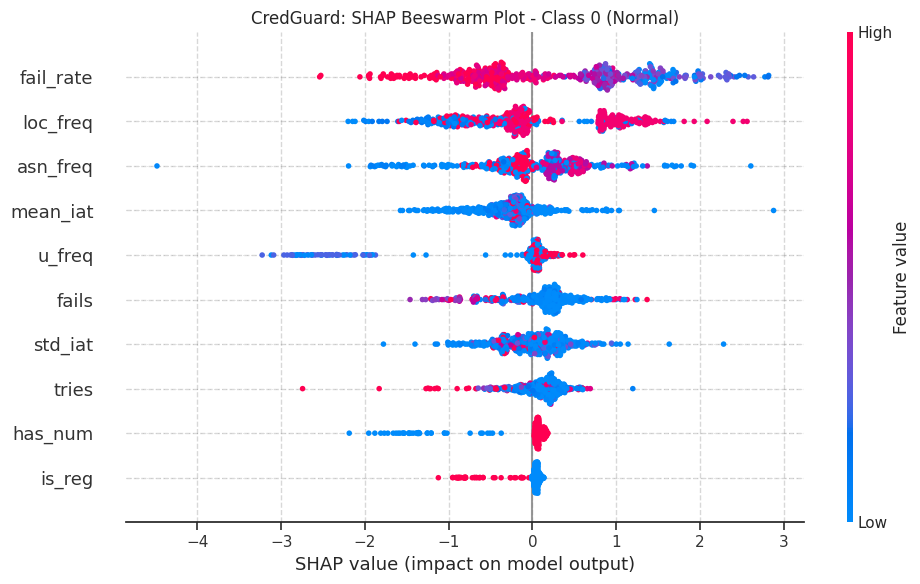


Beeswarm Plot - Class 1 (Attack)


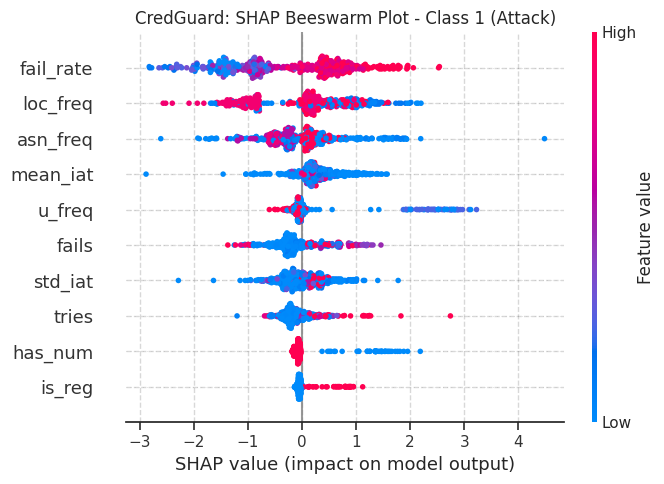

In [27]:
print("\nBeeswarm Plot - Class 0 (Normal)")
shap.summary_plot(
    shap_values_class_0,
    X_sample_for_explainer,
    feature_names=feature_names_list,
    max_display=10,
    plot_type="dot",
    plot_size=(10, 6),
    show=False
)
plt.title("CredGuard: SHAP Beeswarm Plot - Class 0 (Normal)")
plt.grid(True, linestyle='--', alpha=0.3, color='gray')
plt.tight_layout()
plt.show()

print("\nBeeswarm Plot - Class 1 (Attack)")
shap.summary_plot(
    shap_values_class_1,
    X_sample_for_explainer,
    feature_names=feature_names_list,
    max_display=10,
    plot_type="dot",
    plot_size=(7, 5),
    show=False
)
plt.title("CredGuard: SHAP Beeswarm Plot - Class 1 (Attack)")
plt.grid(True, linestyle='--', alpha=0.3, color='gray')
plt.tight_layout()
plt.show()

21. SHAP Global Feature Importance


Global Feature Importance


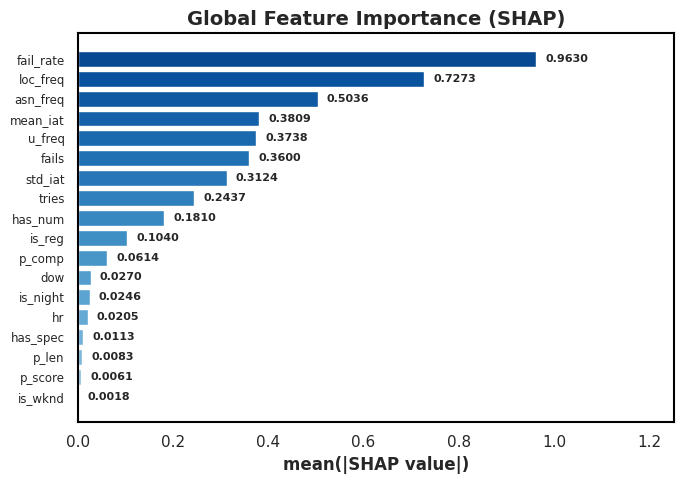

  Feature  mean(|SHAP value|)
fail_rate              0.9630
 loc_freq              0.7273
 asn_freq              0.5036
 mean_iat              0.3809
   u_freq              0.3738
    fails              0.3600
  std_iat              0.3124
    tries              0.2437
  has_num              0.1810
   is_reg              0.1040
   p_comp              0.0614
      dow              0.0270
 is_night              0.0246
       hr              0.0205
 has_spec              0.0113
    p_len              0.0083
  p_score              0.0061
  is_wknd              0.0018


In [28]:
print("\nGlobal Feature Importance")
importance_all = np.mean(np.abs(sv), axis=0)

all_indices = np.arange(len(importance_all))
mask = importance_all > 0.0001
filtered_indices = all_indices[mask]
importance = importance_all[mask]

feature_names = np.array(feature_names_list)[filtered_indices]

indices_sorted = np.argsort(importance)[::-1]
labels_for_plot = feature_names[indices_sorted].tolist()
importance_sorted = importance[indices_sorted]

plt.figure(figsize=(7, 5))

top_n = len(labels_for_plot)
colors = plt.cm.Blues(np.linspace(0.4, 0.9, top_n))

bars = plt.barh(range(top_n), importance_sorted, color=colors[::-1])
plt.yticks(range(top_n), labels_for_plot, fontsize=8.5)
plt.xlabel('mean(|SHAP value|)', fontsize=12, fontweight='bold')
plt.title('Global Feature Importance (SHAP)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.xlim(0, importance_sorted.max() * 1.3)

for spine in plt.gca().spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)
    spine.set_color('black')

for bar, val in zip(bars, importance_sorted):
    plt.text(bar.get_width() + (importance_sorted.max() * 0.02),
             bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

shap_importance_df = pd.DataFrame({
    'Feature': labels_for_plot,
    'mean(|SHAP value|)': importance_sorted.round(4)
})
print(shap_importance_df.to_string(index=False))

22. LIME Explanation

LIME EXPLANATION (XGBOOST):

Random sample selected: 5833
True label: Attack
Model predicted: Attack (confidence: 0.963)
LIME explaining class: Attack

Feature Contributions:
fail_rate                           -> +0.1193
std_iat                             -> +0.1133
fails                               -> -0.0653
tries                               -> -0.0384
has_num                             -> -0.0242
asn_freq                            -> -0.0210
mean_iat                            -> +0.0199
p_comp                              -> -0.0178
dow                                 -> +0.0131
u_freq                              -> +0.0112


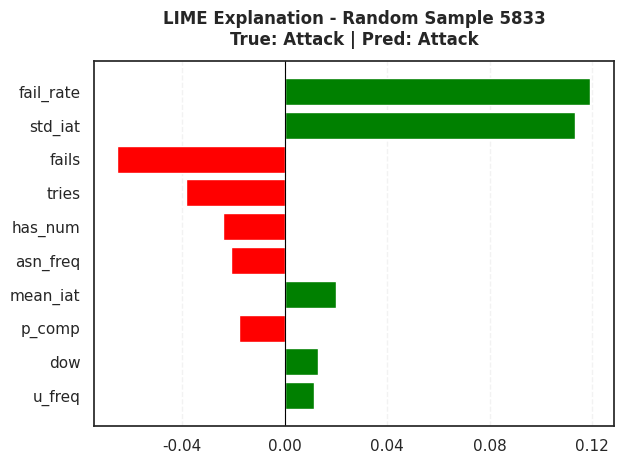

In [29]:

print("LIME EXPLANATION (XGBOOST):")

import numpy as np
import pandas as pd
import random
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

# ==========================================
# 1. Prediction Function
# ==========================================

def predict_proba_lime(X_input):

    X_input = np.atleast_2d(np.asarray(X_input))

    X_input = pd.DataFrame(
        X_input,
        columns=X_train.columns
    )

    return xgb.predict_proba(X_input)


# ==========================================
# 2. Background Dataset
# ==========================================

X_lime_background = X_train.values

lime_feature_names = X_train.columns.tolist()


# ==========================================
# 3. Initialize LIME Explainer
# ==========================================

class_names = ['Normal', 'Attack']

explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_lime_background,
    feature_names=lime_feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=False,
    random_state=42
)


# ==========================================
# 4. Select Random Sample
# ==========================================

sample_idx = random.randint(0, len(X_test) - 1)

sample_values_for_lime = X_test.iloc[sample_idx].values


# ==========================================
# 5. Generate LIME Explanation
# ==========================================

exp = explainer_lime.explain_instance(
    data_row=sample_values_for_lime,
    predict_fn=predict_proba_lime,
    num_features=10
)


# ==========================================
# 6. Model Prediction
# ==========================================

single_sample = sample_values_for_lime.reshape(1, -1)

pred_probs = predict_proba_lime(single_sample)

pred_class_idx = np.argmax(pred_probs, axis=1)[0]

pred_class_name = class_names[pred_class_idx]

confidence = pred_probs[0][pred_class_idx]


# ==========================================
# 7. True Label
# ==========================================

true_label = int(y_test.iloc[sample_idx])

true_label_name = class_names[true_label]


# ==========================================
# 8. LIME Explained Class
# ==========================================

label_from_lime = exp.available_labels()[0]


# ==========================================
# 9. Print Results
# ==========================================

print(f"\nRandom sample selected: {sample_idx}")

print(f"True label: {true_label_name}")

print(
    f"Model predicted: {pred_class_name} "
    f"(confidence: {confidence:.3f})"
)

print(
    f"LIME explaining class: "
    f"{class_names[label_from_lime]}"
)

if true_label != pred_class_idx:
    print("MISCLASSIFICATION!")


# ==========================================
# 10. Feature Contributions
# ==========================================

print("\nFeature Contributions:")

for feature, weight in exp.as_list(label=label_from_lime):
    print(f"{feature:35} -> {weight:+.4f}")


# ==========================================
# 11. Plot LIME Explanation
# ==========================================

fig = exp.as_pyplot_figure(label=label_from_lime)

ax = fig.axes[0]

# Professional title
plt.title(
    f"LIME Explanation - Random Sample {sample_idx}\n"
    f"True: {true_label_name} | Pred: {pred_class_name}",
    fontsize=12,
    fontweight='bold',
    pad=12
)

# X-axis formatting: 2 decimal places
ax.xaxis.set_major_formatter(
    FormatStrFormatter('%.2f')
)

# Control number of intervals
ax.xaxis.set_major_locator(
    MaxNLocator(nbins=6)
)

# Zero reference line
ax.axvline(
    x=0,
    color='black',
    linewidth=0.8
)

# Grid
ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.25
)

ax.set_axisbelow(True)

# Clean layout
plt.tight_layout()

plt.show()


LIME EXPLANATION (XGBOOST)
Model classes: [0 1]

Selected Sample: 15795
True Label: Normal
Model Prediction: Normal (Confidence: 0.6646)
LIME Explained Class: Normal

Feature Contributions:
fail_rate                           -> -0.1181
std_iat                             -> -0.1126
fails                               -> +0.0665
tries                               -> +0.0328
has_num                             -> +0.0260
asn_freq                            -> +0.0222
p_comp                              -> +0.0157
dow                                 -> -0.0144
is_failure                          -> -0.0068
u_freq                              -> -0.0040


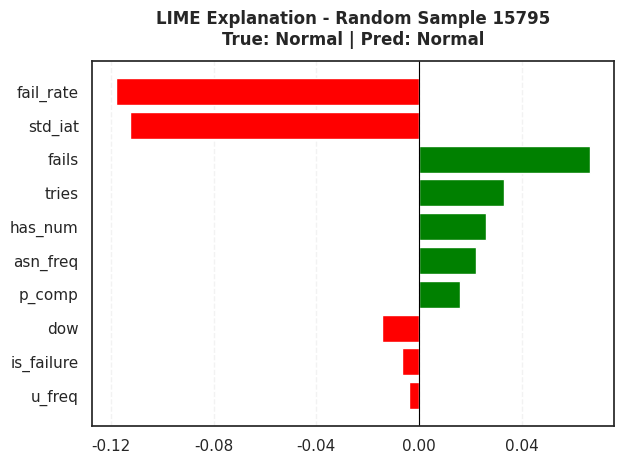

In [30]:

print("LIME EXPLANATION (XGBOOST)")

import numpy as np
import pandas as pd
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

# ==========================================
# 1. Verify Model Classes
# ==========================================

print("Model classes:", xgb.classes_)

assert list(xgb.classes_) == [0, 1], \
    "Expected class order: 0=Normal, 1=Attack"

class_names = ['Normal', 'Attack']

# ==========================================
# 2. Feature Names
# ==========================================

lime_feature_names = X_train.columns.tolist()

assert X_test.columns.tolist() == lime_feature_names, \
    "X_train and X_test features do not match"

# ==========================================
# 3. Prediction Function
# ==========================================

def predict_proba_lime(X_input):

    X_input = np.atleast_2d(np.asarray(X_input))

    X_input = pd.DataFrame(
        X_input,
        columns=lime_feature_names
    )

    return xgb.predict_proba(X_input)

# ==========================================
# 4. Background Dataset
# ==========================================

X_lime_background = X_train.sample(
    n=min(20000, len(X_train)),
    random_state=42
).values

# ==========================================
# 5. Initialize LIME Explainer
# ==========================================

explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_lime_background,
    feature_names=lime_feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=False,
    random_state=42
)

# ==========================================
# 6. Select Random Test Sample
# ==========================================

rng = np.random.RandomState(42)

sample_idx = int(
    rng.randint(0, len(X_test))
)

sample_values_for_lime = X_test.iloc[sample_idx].values

# ==========================================
# 7. Get Model Prediction
# ==========================================

pred_probs = predict_proba_lime(
    sample_values_for_lime
)

pred_class_idx = int(
    np.argmax(pred_probs, axis=1)[0]
)

pred_class_name = class_names[pred_class_idx]

confidence = pred_probs[0][pred_class_idx]

# ==========================================
# 8. Get True Label
# ==========================================

true_label = int(y_test.iloc[sample_idx])

true_label_name = class_names[true_label]

# ==========================================
# 9. Generate LIME Explanation
# Explain the actual predicted class
# ==========================================

label_from_lime = pred_class_idx

exp = explainer_lime.explain_instance(
    data_row=sample_values_for_lime,
    predict_fn=predict_proba_lime,
    num_features=10,
    labels=(label_from_lime,)
)

# ==========================================
# 10. Verify Explanation Class
# ==========================================

print("\nSelected Sample:", sample_idx)

print("True Label:", true_label_name)

print(
    f"Model Prediction: {pred_class_name} "
    f"(Confidence: {confidence:.4f})"
)

print(
    "LIME Explained Class:",
    class_names[label_from_lime]
)

assert label_from_lime == pred_class_idx, \
    "LIME explanation does not match predicted class!"

if true_label != pred_class_idx:
    print("MISCLASSIFICATION!")

# ==========================================
# 11. Feature Contributions
# ==========================================

print("\nFeature Contributions:")

for feature, weight in exp.as_list(label=label_from_lime):

    print(f"{feature:35} -> {weight:+.4f}")

# ==========================================
# 12. Plot LIME Explanation
# ==========================================

fig = exp.as_pyplot_figure(
    label=label_from_lime
)

ax = fig.axes[0]

# Title
plt.title(
    f"LIME Explanation - Random Sample {sample_idx}\n"
    f"True: {true_label_name} | Pred: {pred_class_name}",
    fontsize=12,
    fontweight='bold',
    pad=12
)

# X-axis formatting
ax.xaxis.set_major_formatter(
    FormatStrFormatter('%.2f')
)

ax.xaxis.set_major_locator(
    MaxNLocator(nbins=6)
)

# Zero reference line
ax.axvline(
    x=0,
    color='black',
    linewidth=0.8
)

# Grid
ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.25
)

ax.set_axisbelow(True)

# Final layout
plt.tight_layout()

plt.show()


In [31]:
print("Prediction:", pred_class_idx)
print("Explained labels:", exp.available_labels())
print("Explanation:", exp.as_list(label=pred_class_idx))

Prediction: 0
Explained labels: [0]
Explanation: [('fail_rate', -0.11806086320529537), ('std_iat', -0.11260071291806306), ('fails', 0.06653671837670759), ('tries', 0.03283055868386425), ('has_num', 0.026004421223935436), ('asn_freq', 0.022215335857811467), ('p_comp', 0.015731875202913113), ('dow', -0.014407063434518193), ('is_failure', -0.006824224436580432), ('u_freq', -0.004032145795433541)]


LIME EXPLANATION (XGBoost)
Model classes: [0 1]

Selected sample: 15795
True label: Normal
Model predicted: Normal (confidence: 0.665)
LIME explaining class: Normal

Feature Contributions (Normal Class):
fail_rate                           -> -0.1181
std_iat                             -> -0.1126
fails                               -> +0.0665
tries                               -> +0.0328
has_num                             -> +0.0260
asn_freq                            -> +0.0222
p_comp                              -> +0.0157
dow                                 -> -0.0144
is_failure                          -> -0.0068
u_freq                              -> -0.0040


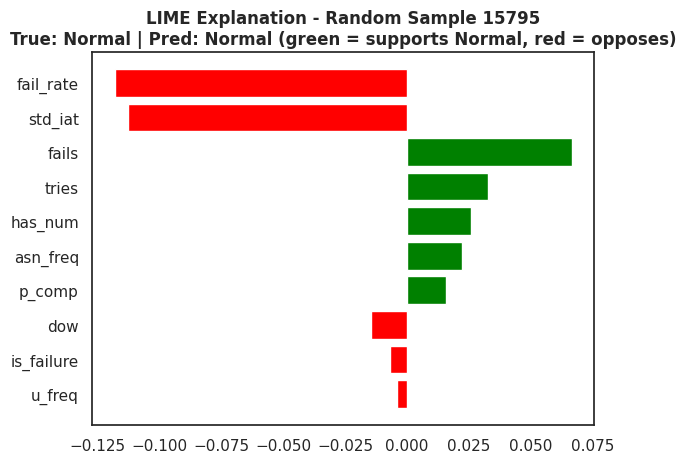

In [32]:
print("LIME EXPLANATION (XGBoost)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lime
import lime.lime_tabular


class_names = ['Normal', 'Attack']

print("Model classes:", xgb.classes_)

assert list(xgb.classes_) == [0, 1], \
    "Check class order: expected 0=Normal, 1=Attack"


lime_feature_names = X_train.columns.tolist()

# 3. Prediction function
def predict_proba_lime(X_input):

    X_input = np.atleast_2d(np.array(X_input))

    X_input = pd.DataFrame(
        X_input,
        columns=lime_feature_names
    )

    return xgb.predict_proba(X_input)


lime_background = X_train.sample(
    n=min(20000, len(X_train)),
    random_state=42
).values


explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=lime_background,
    feature_names=lime_feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=False,
    random_state=42
)


rng = np.random.RandomState(42)

sample_idx = int(
    rng.randint(0, len(X_test))
)

sample_values_for_lime = X_test.iloc[sample_idx].values


pred_probs = predict_proba_lime(sample_values_for_lime)

pred_class_idx = int(
    np.argmax(pred_probs, axis=1)[0]
)

pred_class_name = class_names[pred_class_idx]

confidence = pred_probs[0][pred_class_idx]


true_label = int(y_test.iloc[sample_idx])

true_label_name = class_names[true_label]


explain_class = pred_class_idx

exp = explainer_lime.explain_instance(
    data_row=sample_values_for_lime,
    predict_fn=predict_proba_lime,
    num_features=10,
    labels=(explain_class,)
)

# 10. Print information
print(f"\nSelected sample: {sample_idx}")

print(f"True label: {true_label_name}")

print(
    f"Model predicted: {pred_class_name} "
    f"(confidence: {confidence:.3f})"
)

print(f"LIME explaining class: {pred_class_name}")

if true_label != pred_class_idx:
    print("MISCLASSIFICATION!")

# 11. Feature contributions
print(f"\nFeature Contributions ({pred_class_name} Class):")

for feature, weight in exp.as_list(label=explain_class):
    print(f"{feature:35} -> {weight:+.4f}")

# 12. Plot explanation
fig = exp.as_pyplot_figure(label=explain_class)

plt.title(
    f"LIME Explanation - Random Sample {sample_idx}\n"
    f"True: {true_label_name} | Pred: {pred_class_name} "
    f"(green = supports {pred_class_name}, red = opposes)",
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

LIME EXPLANATION (XGBoost):

Selected sample: 15795
True label: Normal
Model predicted: Normal (confidence: 0.665)
LIME explaining class: Normal

Feature Contributions:
fail_rate                           -> -0.1181
std_iat                             -> -0.1126
fails                               -> +0.0665
tries                               -> +0.0328
has_num                             -> +0.0260
asn_freq                            -> +0.0222
p_comp                              -> +0.0157
dow                                 -> -0.0144
is_failure                          -> -0.0068
u_freq                              -> -0.0040


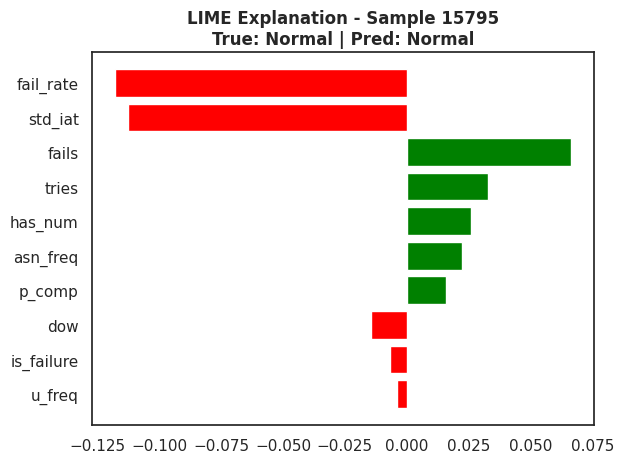

In [33]:
print("LIME EXPLANATION (XGBoost):")

lime_feature_names = X_train.columns.tolist()

def predict_proba_lime(X_input):
    X_input = np.atleast_2d(np.array(X_input))
    return xgb.predict_proba(pd.DataFrame(X_input, columns=lime_feature_names))

lime_background = X_train.sample(n=min(20000, len(X_train)), random_state=42).values

explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=lime_background,
    feature_names=lime_feature_names,
    class_names=class_names,
    mode='classification',
    discretize_continuous=False,
    random_state=42
)

rng = np.random.RandomState(42)
sample_idx = int(rng.randint(0, len(X_test)))
sample_values_for_lime = X_test.iloc[sample_idx].values

pred_probs = predict_proba_lime(sample_values_for_lime)
pred_class_idx = int(np.argmax(pred_probs, axis=1)[0])
pred_class_name = class_names[pred_class_idx]
confidence = pred_probs[0][pred_class_idx]

true_label = int(y_test.iloc[sample_idx])
true_label_name = class_names[true_label]

exp = explainer_lime.explain_instance(
    data_row=sample_values_for_lime,
    predict_fn=predict_proba_lime,
    num_features=10,
    labels=(pred_class_idx,)
)
label_from_lime = pred_class_idx

print(f"\nSelected sample: {sample_idx}")
print(f"True label: {true_label_name}")
print(f"Model predicted: {pred_class_name} (confidence: {confidence:.3f})")
print(f"LIME explaining class: {class_names[label_from_lime]}")

if true_label != pred_class_idx:
    print("MISCLASSIFICATION!")

print("\nFeature Contributions:")
for feature, weight in exp.as_list(label=label_from_lime):
    print(f"{feature:35} -> {weight:+.4f}")

fig = exp.as_pyplot_figure(label=label_from_lime)
plt.title(
    f"LIME Explanation - Sample {sample_idx}\nTrue: {true_label_name} | Pred: {pred_class_name}",
    fontsize=12,
    fontweight='bold'
)
plt.tight_layout()
plt.show()

23. Final Summary with All Metrics

In [34]:
start_time = time.time()
xgb.predict_proba(X_test)
end_time = time.time()
inference_speed = (end_time - start_time) / len(X_test)

far_rate_ratio = 1 - normal_recall

print("\n" + "=" * 70)
print("FINAL SUMMARY - ALL METRICS")
print("=" * 70)

print(f"""╔══════════════════════════════════════════════════════════╗
║                 MODEL PERFORMANCE SUMMARY                ║
╠══════════════════════════════════════════════════════════╣
║
║  ACCURACY:
║  • Training: {train_acc:.2%}
║  • Test: {test_acc:.2%}
║  • Validation: {val_acc:.2%}
║
║  SECURITY METRICS:
║  • Attack Detection Rate (Recall): {attack_recall:.2%}
║  • False Alarm Rate: {far_rate_ratio:.2%}
║  • System Reliability (Attack Precision): {report['Attack']['precision']:.2%}
║
║  MODEL EFFICIENCY:
║  • Overall Accuracy: {test_acc:.2%}
║  • F1-Score (Weighted): {test_f1:.2%}
║  • Inference Speed: {inference_speed*1000:.4f} ms/sample
║
║  PER-CLASS F1-SCORES:
║  • Normal: {report['Normal']['f1-score']:.2%}
║  • Attack: {report['Attack']['f1-score']:.2%}
║
║  TOP FEATURES INFLUENCING DETECTION:
║  1. {top_features.iloc[0]['Feature']}
║  2. {top_features.iloc[1]['Feature']}
║  3. {top_features.iloc[2]['Feature']}
║
║  DATA DISTRIBUTION:
║  • Total samples: {len(df)}
║  • Features used: {len(X_train.columns)}
║  • Train/Test/Val: {len(X_train)}/{len(X_test)}/{len(X_val)}
║
╚══════════════════════════════════════════════════════════╝
""")


FINAL SUMMARY - ALL METRICS
╔══════════════════════════════════════════════════════════╗
║                 MODEL PERFORMANCE SUMMARY                ║
╠══════════════════════════════════════════════════════════╣
║
║  ACCURACY:
║  • Training: 90.69%
║  • Test: 81.32%
║  • Validation: 87.15%
║
║  SECURITY METRICS:
║  • Attack Detection Rate (Recall): 76.91%
║  • False Alarm Rate: 15.28%
║  • System Reliability (Attack Precision): 79.45%
║
║  MODEL EFFICIENCY:
║  • Overall Accuracy: 81.32%
║  • F1-Score (Weighted): 81.29%
║  • Inference Speed: 0.0058 ms/sample
║
║  PER-CLASS F1-SCORES:
║  • Normal: 83.69%
║  • Attack: 78.16%
║
║  TOP FEATURES INFLUENCING DETECTION:
║  1. has_num
║  2. fail_rate
║  3. p_comp
║
║  DATA DISTRIBUTION:
║  • Total samples: 1003030
║  • Features used: 23
║  • Train/Test/Val: 755190/118512/129328
║
╚══════════════════════════════════════════════════════════╝

